# 4. What WIEMIP can already tell us

This notebook summarises the WIEMIP 1pctCO2 land results for the process-model questions of notebooks 1
to 3. It reads tables written by two scripts (no sampling):

* `scripts/wiemip_extract.py` (run on the WIEMIP hub) takes the global land carbon of every model,
  factorial and run from `wiemip_registry` into `data/wiemip/`;
* `scripts/wiemip_values.py` and `scripts/wiemip_power.py` compute β_L, γ_L, the paired process effects
  and the detection power into `results/wiemip/`.

**What is not yet possible.** There is no table of which processes each model includes. The factorial
runs prove that a process is present (a model that ran noFire has fire) but never that it is absent, so
the flag budget, the cross-model regression and the demography question wait for that table
(`data/wiemip/flags_template.csv` is a starting point). The runs are land only, so TCRE, the carbon
factor R and the airborne fraction cannot be computed either.

**Status.** The open `data-quality` issues on `WIEMIP/wiemip-data-registry` have not been read for this
version; treat single-model values as provisional.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tcre_evidence import plotting as pl
from tcre_evidence.paths import DATA, RESULTS

pl.style()
pd.set_option("display.precision", 2)
W = RESULTS / "wiemip"
fb = pd.read_csv(W / "feedbacks_long.csv")
pe = pd.read_csv(W / "paired_effects.csv")
pw = pd.read_csv(W / "power_paired.csv")
pdz = pd.read_csv(W / "power_designs.csv")
scr = pd.read_csv(W / "screening.csv")
cmip6 = pd.read_csv(DATA / "examples" / "cmip6_land_feedbacks.csv").set_index("model")
prov = json.loads((DATA / "wiemip" / "provenance.json").read_text())
base = fb[fb.factorial == "baseline"]
uk = base[base.pattern == "ukesm"].set_index("model")
PAT = {"ukesm": pl.SERIES[0], "gfdl": pl.SERIES[1], "ipsl": pl.SERIES[2]}
print(f"extracted {prov['created']} from {prov['data_root']}; {prov['n_runs']} runs; "
      f"{fb.model.nunique()} models; dT = {fb.dT.iloc[0]:.3f} K, dCa = {fb.dCa.iloc[0]:.1f} ppm (years 61-80)")

extracted 2026-10-22T21:31:36+00:00 from /srv/wiemip; 208 runs; 18 models; dT = 1.742 K, dCa = 280.0 ppm (years 61-80)


## 1. How the WIEMIP setting differs from C4MIP

* **Prescribed climate.** Every model is driven by the same FaIR median warming, pattern scaled with one
  of three GCM patterns (UKESM, GFDL, IPSL). ΔT is therefore the same for every model and pattern
  (1.74 K at years 61 to 80), and differences in γ_L come from the land models alone. In CMIP6 they also
  include each ESM's own climate response.
* **BGC without warming.** BGC and ctrl use a constant climate, so ΔT_BGC = 0 and
  β_coubgc = ΔC_BGC / ΔCa, with no correction for BGC warming.
* **Factorials.** Many models repeated ctrl, BGC and COU with one process switched off. These pairs give
  the process effect within one model directly; in CMIP6 it could only be inferred from differences
  between models.

## 2. β_L and γ_L of the 18 models

Baseline runs, UKESM pattern (the only pattern every model ran). CMIP6 (C4MIP 1pctCO2, same window and
convention) is shown in grey for scale.

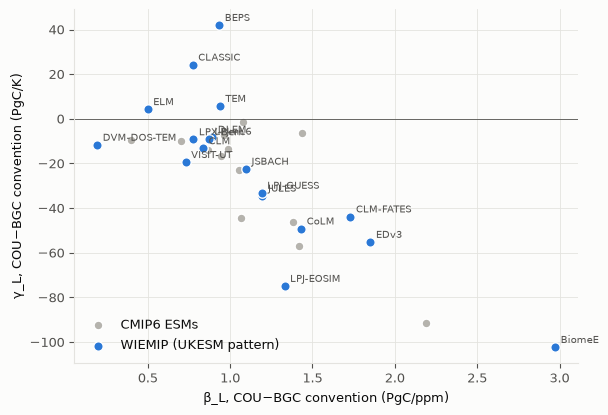

,n,median,p10,p90,sd
β_L WIEMIP,18.0,0.94,0.66,1.77,0.61
β_L CMIP6,13.0,1.05,0.74,1.43,0.43
γ_L WIEMIP,18.0,-16.35,-61.09,11.26,34.49
γ_L CMIP6,13.0,-13.89,-54.93,-6.52,26.24


In [2]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.scatter(cmip6.beta_land_coubgc, cmip6.gamma_land_coubgc, s=40, color="#b5b3ad", label="CMIP6 ESMs",
           edgecolor="white", linewidth=1, zorder=2)
ax.scatter(uk.beta_land_coubgc, uk.gamma_land_coubgc, s=46, color=pl.SERIES[0], label="WIEMIP (UKESM pattern)",
           edgecolor="white", linewidth=1, zorder=3)
for m, r in uk.iterrows():
    ax.annotate(m.replace("_", "-"), (r.beta_land_coubgc, r.gamma_land_coubgc), fontsize=7,
                xytext=(4, 3), textcoords="offset points", color=pl.TEXT2)
ax.axhline(0, color=pl.TEXT2, lw=0.6)
ax.set(xlabel="β_L, COU−BGC convention (PgC/ppm)", ylabel="γ_L, COU−BGC convention (PgC/K)")
ax.legend(loc="lower left")
plt.show()

def spread(s):
    return pd.Series(dict(n=s.size, median=s.median(), p10=s.quantile(0.1), p90=s.quantile(0.9), sd=s.std()))

pd.DataFrame({"β_L WIEMIP": spread(uk.beta_land_coubgc), "β_L CMIP6": spread(cmip6.beta_land_coubgc),
              "γ_L WIEMIP": spread(uk.gamma_land_coubgc), "γ_L CMIP6": spread(cmip6.gamma_land_coubgc)}).T

**Reading the figure and table.**
* **Spread.** With the climate shared, the land models alone span a range of β_L and γ_L at least as wide
  as the CMIP6 ESMs:
  * β_L: 10 to 90 % range 0.66 to 1.77 PgC/ppm, against 0.74 to 1.43 in CMIP6;
  * γ_L: −61 to +11 PgC/K, against −55 to −7 PgC/K.
* **Positive γ_L.** Four models have a positive γ_L (BEPS, CLASSIC, TEM, ELM); no CMIP6 ESM does (its
  largest value is −1.2 PgC/K).
  * BEPS has a drifting ctrl run (section 7).
  * CLASSIC is positive only in the COU−BGC convention (section 4).
* **BiomeE** is far from the others in both quantities (β_L 2.97 PgC/ppm, γ_L −102 PgC/K) and should be
  checked against the group's own diagnostics before it enters a fit.
* **Not a like-for-like comparison of γ_L.** ΔT is 1.74 K for every WIEMIP model, whereas each CMIP6 ESM
  warms by its own TCR. The γ_L values are comparable, but ΔC = γ_L·ΔT is not.

## 3. How much the climate pattern matters

Ten models ran COU with all three patterns. The global warming is the same in each; only its distribution
differs.

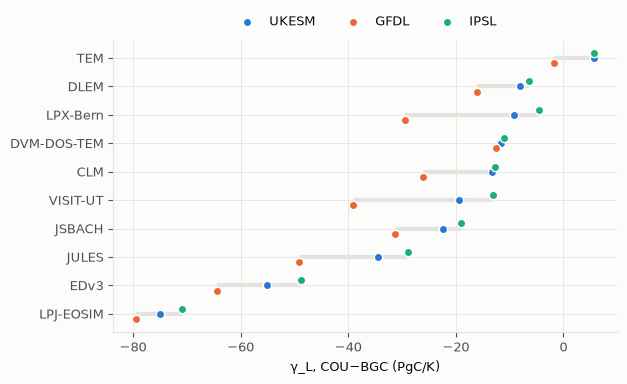

pattern effect on γ_L across these models (PgC/K):
       GFDL − UKESM  IPSL − UKESM
count          10.0          10.0
mean          -10.6           3.3
std             6.3           2.4
min           -20.2          -0.0
max            -0.8           6.4

spread between these models (sd of the UKESM column): 24.3 PgC/K


In [3]:
g = base.pivot_table(index="model", columns="pattern", values="gamma_land_coubgc").dropna()
g = g.loc[g.ukesm.sort_values().index]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
y = np.arange(len(g))
ax.hlines(y, g.min(axis=1), g.max(axis=1), color=pl.GRID, lw=3, zorder=1)
for (p, c), off in zip(PAT.items(), (0.0, -0.18, 0.18)):
    ax.scatter(g[p], y + off, color=c, s=36, label=p.upper(), zorder=3, edgecolor="white", linewidth=1)
ax.set_yticks(y, [m.replace("_", "-") for m in g.index])
ax.set(xlabel="γ_L, COU−BGC (PgC/K)")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.show()
d = pd.DataFrame({"GFDL − UKESM": g.gfdl - g.ukesm, "IPSL − UKESM": g.ipsl - g.ukesm})
print("pattern effect on γ_L across these models (PgC/K):")
print(d.describe().loc[["count", "mean", "std", "min", "max"]].round(1).to_string())
print(f"\nspread between these models (sd of the UKESM column): {g.ukesm.std():.1f} PgC/K")

**Reading the figure.** Each row is a model and each dot one pattern.
* **GFDL is the most negative.** The GFDL pattern gives the most negative γ_L in every model, on average by
  11 PgC/K relative to UKESM (from 1 to 20 PgC/K). IPSL is 3 PgC/K less negative than UKESM on average.
* **The ranking holds.** Models keep roughly the same order whichever pattern is used.
* **Size of the effect.** The pattern effect is smaller than the spread between models (sd 24 PgC/K for
  these ten models), but comparable to the process effects in section 5.
* **Consequence for the translation function.** A function that translates WIEMIP effects to an ESM
  should carry the pattern, or at least its uncertainty.
* **Consequence for CMIP6.** Part of the CMIP6 spread in γ_L comes from each ESM's own warming pattern,
  which a regression on land-process flags does not represent.

## 4. The two γ conventions and the non-linear term

Fourteen models ran RAD (warming at constant CO2). γ_rad = ΔC_RAD/ΔT and ε = ΔC_COU − ΔC_BGC − ΔC_RAD.

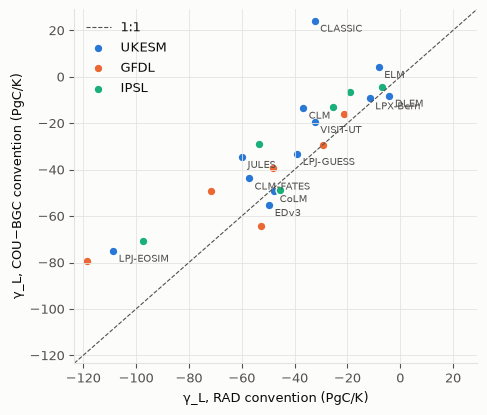

,gamma_land_coubgc,gamma_land_rad,eps_land
model,,,
EDv3,-55.18,-49.60,-9.70
DLEM,-8.09,-4.10,-6.95
CoLM,-49.20,-47.71,-2.58
LPX_Bern,-9.23,-11.57,4.07
LPJ_GUESS,-33.19,-39.02,10.15
ELM,4.29,-8.16,21.68
VISIT_UT,-19.43,-32.34,22.50
CLM_FATES,-43.80,-57.24,23.41
CLM,-13.27,-36.72,40.84


In [4]:
r = base.dropna(subset=["gamma_land_rad"])
fig, ax = plt.subplots(figsize=(5.2, 4.6))
lim = [min(r.gamma_land_rad.min(), r.gamma_land_coubgc.min()) - 5, max(r.gamma_land_rad.max(), r.gamma_land_coubgc.max()) + 5]
ax.plot(lim, lim, color=pl.TEXT2, lw=0.8, ls="--", label="1:1")
for p, c in PAT.items():
    s = r[r.pattern == p]
    ax.scatter(s.gamma_land_rad, s.gamma_land_coubgc, color=c, s=40, label=p.upper(), edgecolor="white", linewidth=1)
for _, row in r[r.pattern == "ukesm"].iterrows():
    ax.annotate(row.model.replace("_", "-"), (row.gamma_land_rad, row.gamma_land_coubgc), fontsize=7,
                xytext=(4, -8), textcoords="offset points", color=pl.TEXT2)
ax.set(xlim=lim, ylim=lim, xlabel="γ_L, RAD convention (PgC/K)", ylabel="γ_L, COU−BGC convention (PgC/K)")
ax.legend(loc="upper left")
plt.show()
r[r.pattern == "ukesm"].set_index("model")[["gamma_land_coubgc", "gamma_land_rad", "eps_land"]].sort_values("eps_land")

**Reading the figure and table.**
* **Direction.** In 9 of the 12 models, γ_rad is more negative than γ_coubgc.
* **ε.** ε is positive in 9 of 12 models (median 22 PgC; range −10 to +99 PgC). Under higher CO2, the
  same warming costs less land carbon in these models than it does at constant CO2.
* **CLASSIC** is the extreme case. Its sign changes between conventions: γ_coubgc is +24 PgC/K and
  γ_rad is −32 PgC/K.
* **Keep the conventions apart.** As with CMIP6, the two conventions should not be mixed in one column,
  and every table here names the convention it uses.

## 5. Process effects measured within models

Each point is one model: the factorial pair that differs by one process, process on minus off (UKESM
pattern; where a model has more than one such pair, for example fire with and without nitrogen, the pair
against the baseline is shown). For β_L the effect is the ratio η = β_on / β_off, the same definition as
the development code's paired inputs; for γ_L it is δ = γ_on − γ_off.

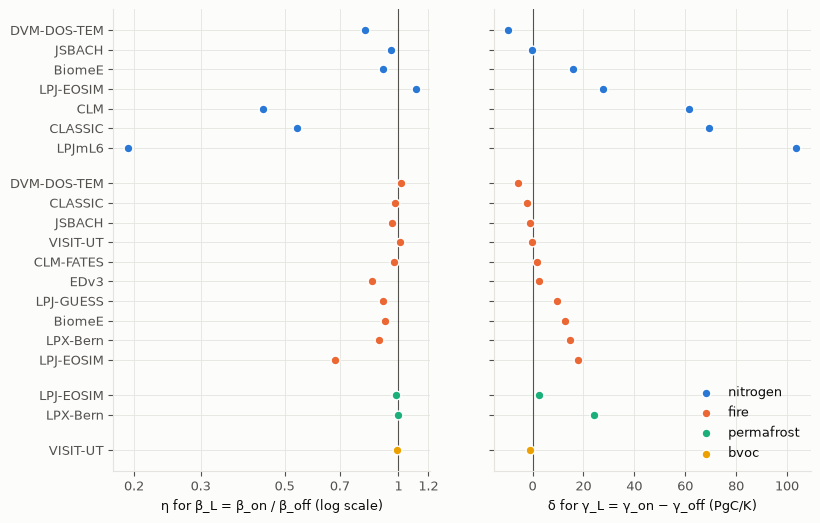

eta_beta_land  delta_gamma_land_coubgc  dC_cou_ratio
process    model                                                            
nitrogen   DVM_DOS_TEM           0.82                    -9.54          0.54
           JSBACH                0.96                    -0.01          0.95
           BiomeE                0.91                    15.79          0.92
           LPJ_EOSIM             1.11                    27.53          1.55
           CLM                   0.44                    61.56          0.52
           CLASSIC               0.54                    69.46          0.80
           LPJmL6                0.19                   103.73          0.21
fire       DVM_DOS_TEM           1.01                    -5.82          0.78
           CLASSIC               0.98                    -2.15          0.97
           JSBACH                0.96                    -1.14          0.95
           VISIT_UT              1.01                    -0.09          1.01
           CLM_FATES             0.97                     1.96          0.97
           EDv3                  0.85                     2.73          0.83
           LPJ_GUESS             0.91                     9.82          0.95
           BiomeE                0.92                    12.93          0.93
           LPX_Bern              0.89                    14.73          0.99
           LPJ_EOSIM             0.68                    17.99          0.63
permafrost LPJ_EOSIM             0.98                     2.58          0.99
           LPX_Bern              1.00                    24.11          1.26
bvoc       VISIT_UT              0.99                    -1.15          0.98

In [5]:
pe["background"] = pe.background.fillna("none")
procs = ["nitrogen", "fire", "permafrost", "bvoc"]
p1 = pe[(pe.pattern == "ukesm") & (pe.background == "none")].copy()
p1["order"] = p1.process.map(procs.index)
p1 = p1.sort_values(["order", "delta_gamma_land_coubgc"]).reset_index(drop=True)
ypos = np.arange(len(p1)) + 0.8 * p1.order.values  # a gap between processes
fig, axs = plt.subplots(1, 2, figsize=(9, 6), sharey=True)
for ax, col, lab, ref in [(axs[0], "eta_beta_land", "η for β_L = β_on / β_off (log scale)", 1.0),
                          (axs[1], "delta_gamma_land_coubgc", "δ for γ_L = γ_on − γ_off (PgC/K)", 0.0)]:
    ax.axvline(ref, color=pl.TEXT2, lw=0.8)
    for i, p in enumerate(procs):
        k = (p1.process == p).values
        ax.scatter(p1.loc[k, col], ypos[k], color=pl.SERIES[i], s=40, edgecolor="white", linewidth=1,
                   zorder=3, label=p)
    ax.set_xlabel(lab)
axs[0].set_xscale("log")
axs[0].set_xticks([0.2, 0.3, 0.5, 0.7, 1.0, 1.2], ["0.2", "0.3", "0.5", "0.7", "1", "1.2"])
axs[0].minorticks_off()
axs[0].set_yticks(ypos, [m.replace("_", "-") for m in p1.model])
axs[0].invert_yaxis()
axs[1].legend(loc="lower right")
plt.show()

# the end-to-end land response in COU (beta and gamma together): land carbon gain with the process on / off
w = fb[fb.pattern == "ukesm"].set_index(["model", "factorial"]).dC_land_cou
p1["dC_cou_ratio"] = [w[(r.model, r.factorial_on)] / w[(r.model, r.factorial_off)] for r in p1.itertuples()]
p1.set_index(["process", "model"])[["eta_beta_land", "delta_gamma_land_coubgc", "dC_cou_ratio"]].round(2)

In [6]:
# the same effects for every pattern and background: does the pattern or the other switched-off process change them?
pe.pivot_table(index=["process", "model", "background"], columns="pattern",
               values="delta_gamma_land_coubgc").round(1)

pattern                            gfdl  ipsl  ukesm
process    model       background                   
bvoc       VISIT_UT    none        -0.9  -0.8   -1.2
fire       BiomeE      none         NaN   NaN   12.9
           CLASSIC     nitrogen     NaN   NaN   -1.6
                       none         NaN   NaN   -2.2
           CLM_FATES   none         NaN   NaN    2.0
           DVM_DOS_TEM none        -9.7 -10.1   -5.8
           EDv3        none         NaN   NaN    2.7
           JSBACH      none         0.3  -0.3   -1.1
           LPJ_EOSIM   none        19.3  10.4   18.0
           LPJ_GUESS   none         NaN   NaN    9.8
           LPX_Bern    none        14.0  16.2   14.7
                       permafrost  12.8  14.7   13.0
           VISIT_UT    none        -0.2   0.3   -0.1
nitrogen   BiomeE      none         NaN   NaN   15.8
           CLASSIC     fire         NaN   NaN   70.0
                       none         NaN   NaN   69.5
           CLM         none         NaN   NaN   61.6
           DVM_DOS_TEM none        -5.6  -4.9   -9.5
           JSBACH      none        -1.4  -1.9   -0.0
           LPJ_EOSIM   none        21.0  17.1   27.5
           LPJmL6      none         NaN   NaN  103.7
permafrost LPJ_EOSIM   none         0.7   2.7    2.6
           LPX_Bern    fire        17.1  22.8   22.4
                       none        18.3  24.4   24.1

**Reading the figure and tables.** `dC_cou_ratio` is the land carbon gained in COU with the process on,
divided by that with it off. It combines the β and γ effects, so it is the closest land-only quantity to
the end-to-end effect.

* **Nitrogen has the largest effect, and the most varied.** With nitrogen on:
  * β_L is reduced in most models, with η from 0.19 (LPJmL6) to 1.11 (LPJ-EOSIM); the geometric mean is
    0.62.
  * γ_L becomes less negative in five of seven models (δ up to +104 PgC/K).
  * The two effects partly cancel: the COU land gain falls by a geometric mean factor of 0.68.
  * The ratio ranges from 0.21 (LPJmL6) to 1.55 (LPJ-EOSIM). LPJ-EOSIM is the only model whose land
    takes up more carbon with nitrogen on, and its runs should be checked with the group.
* **Fire has a small average effect.** With fire on:
  * β_L is reduced by about 9 % (η from 0.68 to 1.01);
  * γ_L becomes less negative by 5 PgC/K on average (−6 to +18), positive in 6 of 10 models;
  * the COU land gain falls by a geometric mean factor of 0.89.
  * LPJ-EOSIM has the largest fire effect on every measure.
* **Permafrost (two models) and BVOC (one model) are too few to generalise.** LPJ-EOSIM and LPX-Bern
  differ by a factor of ten in δ for γ_L (2.6 against 24 PgC/K).
* **Stable across patterns and backgrounds.** Within a model, the effects change little between patterns
  (second table). They also change little when another process is already off:
  * fire in CLASSIC, with and without nitrogen;
  * fire in LPX-Bern, with and without permafrost.
  In these few cases the effects combine roughly additively.
* **Definitions may differ.** "Process off" can be implemented differently in each model (for example,
  nitrogen removed against nitrogen set non-limiting). Part of the spread between models may come from
  that, and the protocol should be checked before the spread is read as structural.

## 6. Paired runs against regression across models

Without the flag table the real flag regression cannot be run, but its precision can be bounded. The
standard error of a flag effect estimated across 18 models depends on the scatter the flags leave
unexplained and on how many models carry the flag. `scripts/wiemip_power.py` computes it for 3 to 15
flagged models (with three further flags set at random), using the WIEMIP spread (all of it, or less 20 %
explained, as for γ_L in CMIP6; and a robust spread that limits the weight of single models). The paired
estimate's standard error is the between-model sd of the paired effects over √n.

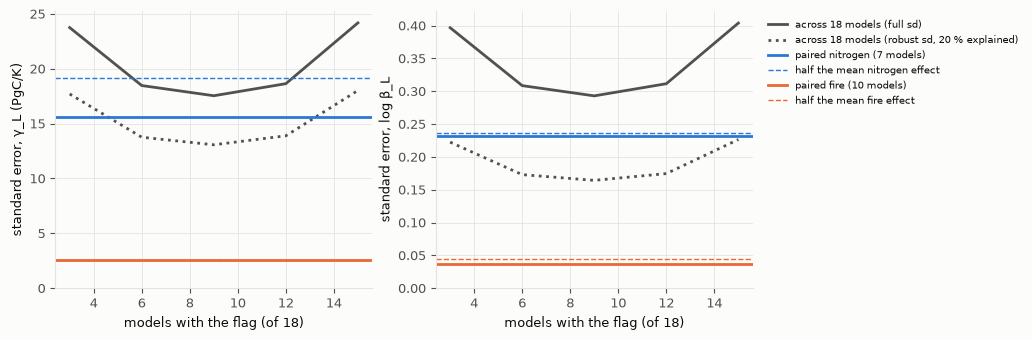

,quantity,process,n_pairs,mean_effect,sd_between_models,se_paired,n_needed_sd_r2_0.0,n_needed_robust_sd_r2_0.2
1,gamma_land_coubgc,fire,10,5.09,8.14e+00,2.57e+00,736.0,410.0
2,gamma_land_coubgc,nitrogen,7,38.36,4.12e+01,1.56e+01,18.0,12.0
3,gamma_land_coubgc,permafrost,2,13.34,1.52e+01,1.08e+01,110.0,62.0
5,beta_land_coubgc,fire,10,-0.09,1.18e-01,3.70e-02,662.0,212.0
6,beta_land_coubgc,nitrogen,7,-0.47,6.14e-01,2.32e-01,26.0,12.0
7,beta_land_coubgc,permafrost,2,-0.01,9.00e-03,7.00e-03,inf,inf


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (q, lab) in zip(axs, [("gamma_land_coubgc", "γ_L (PgC/K)"), ("beta_land_coubgc", "log β_L")]):
    for (sc, r2), c, ls in [(("sd", 0.0), pl.TEXT2, "-"), (("robust_sd", 0.2), pl.TEXT2, ":")]:
        s = pdz[(pdz.quantity == q) & (pdz.scatter == sc) & (pdz.r2 == r2)]
        ax.plot(s.n_flagged, s.se_cross_model, color=c, ls=ls,
                label=f"across 18 models ({'full sd' if sc == 'sd' else 'robust sd, 20 % explained'})")
    for i, p in enumerate(["nitrogen", "fire"]):
        row = pw[(pw.quantity == q) & (pw.process == p)].iloc[0]
        ax.axhline(row.se_paired, color=pl.SERIES[i], lw=2, label=f"paired {p} ({row.n_pairs} models)")
        ax.axhline(abs(row.mean_effect) / 2, color=pl.SERIES[i], lw=1, ls="--",
                   label=f"half the mean {p} effect")
    ax.set(xlabel="models with the flag (of 18)", ylabel=f"standard error, {lab}", ylim=(0, None))
axs[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()
cols = ["quantity", "process", "n_pairs", "mean_effect", "sd_between_models", "se_paired",
        "n_needed_sd_r2_0.0", "n_needed_robust_sd_r2_0.2"]
pw[pw.n_pairs > 1][cols].round(3)

**Reading the figure and table.** Solid and dotted grey lines are the cross-model standard error; coloured
solid lines are the paired standard error; dashed lines are half the mean paired effect (an effect is
detected at two standard errors where its error falls below that line).

* **Fire.**
  * The paired runs measure the mean fire effect on γ_L to ±2.6 PgC/K. A regression across 18 models
    could at best reach ±13 PgC/K.
  * Detecting the mean fire effect across models would need about 400 to 740 independent models for γ_L
    (210 to 660 for β_L).
  * Even the paired mean (+5.1 ± 2.6 PgC/K) is only about two standard errors from zero.
  * For fire, the factorial runs are the only usable evidence.
* **Nitrogen.**
  * The effect is large enough to be detected across models with about 12 to 26 models, close to the
    18 available.
  * The paired standard error (±16 PgC/K on γ_L, ±0.23 in log β_L) is no smaller than the cross-model
    one. The effect varies widely between models (sd 41 PgC/K; sd 0.61 in log β_L, about a factor of
    1.8), and that variation, not measurement, limits both estimates.
  * For a translation function, this variation is the result. A single nitrogen factor would describe
    individual models poorly, and the process-scatter term (`sigma_process_struct`,
    `sigma_mult_struct`) can now be set from these values rather than assumed.
* **With the flag table.** Once flags are available for all models, nitrogen is where the cross-model
  estimate and the paired estimate can be compared directly.

## 7. Data checks

In [8]:
print("runs dropped:")
print(scr.dropna(subset=["reason"])[["model", "factorial", "sim_forcing", "reason"]].to_string(index=False))
print("\nctrl drift beyond 5 PgC per century:")
print(scr[scr.ctrl_drift_pgc_per_century.abs() > 5].drop_duplicates(["model", "factorial"])
      [["model", "factorial", "ctrl_drift_pgc_per_century"]].round(1).to_string(index=False))

runs dropped:
model         factorial sim_forcing                      reason
JULES noFire_noNitrogen  bgc/stable non-finite values in window
JULES noFire_noNitrogen   cou/ukesm non-finite values in window

ctrl drift beyond 5 PgC per century:
      model  factorial  ctrl_drift_pgc_per_century
       BEPS   baseline                        62.5
     BiomeE noNitrogen                         6.4
       CoLM   baseline                         8.1
       DLEM   baseline                         7.4
DVM_DOS_TEM   baseline                         6.1
DVM_DOS_TEM     noFire                         5.7
        ELM     noFire                        22.7
  LPJ_GUESS   baseline                        14.4
  LPJ_GUESS     noFire                        12.6
     LPJmL6 noNitrogen                        -5.4


**Reading the output.**
* **JULES noFire_noNitrogen** has non-finite values in BGC and COU (probably an unmasked fill value) and
  is excluded.
* **Drift.** The BEPS ctrl run drifts by 62 PgC per century; LPJ-GUESS and the ELM noFire ctrl by 13 to
  23 PgC per century. Anomalies are taken against the ctrl run over the same years, which removes a
  common drift to first order. A drift that differs between runs would remain and would bias γ_L for
  these models. ELM noFire has no COU run, so it gives no paired effect.
* **Not yet checked.** The open `data-quality` issues for these models have not been read.

## Summary

**What WIEMIP already shows** (1pctCO2, 2×CO2 window, prescribed FaIR median climate):
1. **Spread.** Land models under a shared climate span β_L and γ_L at least as widely as the CMIP6 ESMs,
   and four of 18 have a positive γ_L in the COU−BGC convention.
2. **Pattern.** The climate pattern alone shifts γ_L by up to 20 PgC/K (GFDL most negative). This is
   smaller than the spread between models but similar to the process effects.
3. **Nitrogen.**
   * It has the largest process effect: it reduces β_L and the magnitude of γ_L, which partly cancel.
   * Its size varies greatly between models: η for β_L from 0.19 to 1.11, and the COU land gain ratio
     from 0.21 to 1.55.
   * The spread between models is better constrained than the mean.
4. **Fire.**
   * Its average effect is small: β_L × 0.91 and γ_L +5 ± 3 PgC/K.
   * A comparison across models could not detect it at any feasible ensemble size, so the factorial runs
     are the only evidence on it.
5. **Convention.** The γ convention matters: ε has a median of +22 PgC, and one model changes sign
   between conventions.

**What needs more information**
* **Needs the flag table** (with the zeros, demography and families):
  * the flag budget and the cross-model regression;
  * the comparison of cross-model and paired estimates;
  * leave-one-family-out;
  * the demography question.
* **Needs an ocean and a climate response:** TCRE, R and the airborne fraction (for example, CMIP6 ocean
  uptake as a stated approximation).
* **Needs checking:** the open `data-quality` issues, BiomeE, the LPJ-EOSIM nitrogen response, the BEPS
  drift, and how each group implemented "process off".